In [2]:
from statistics import NormalDist

import numpy as np
import pandas as pd
import cvxpy as cp

from power_system_data import PowerSystemData, build_gsk
from network_plot import plot_network
from market_model import solve_base_case, solve_redispatch, select_cne, gsk_online, build_flow_based, da_zonal_clearing

In [3]:
data_crossborder = PowerSystemData.from_csv('../data/test_crossborder_congestion')
data_nodal_zones = PowerSystemData.from_csv('../data/test_nodal_zones')
data_no_congestion = PowerSystemData.from_csv('../data/test_no_congestion')

In [4]:
bc_crossborder = solve_base_case(data_crossborder, verbose=False)
bc_nodal_zones = solve_base_case(data_nodal_zones,verbose=False)
bc_no_congestion = solve_base_case(data_no_congestion,verbose=False)

Set parameter Username
Set parameter LicenseID to value 2874629
Academic license - for non-commercial use only - expires 2027-10-14


<Axes: title={'left': 'Base case — total cost 2160.0 €   (arrow = flow direction, width = loading, red = binding)'}>

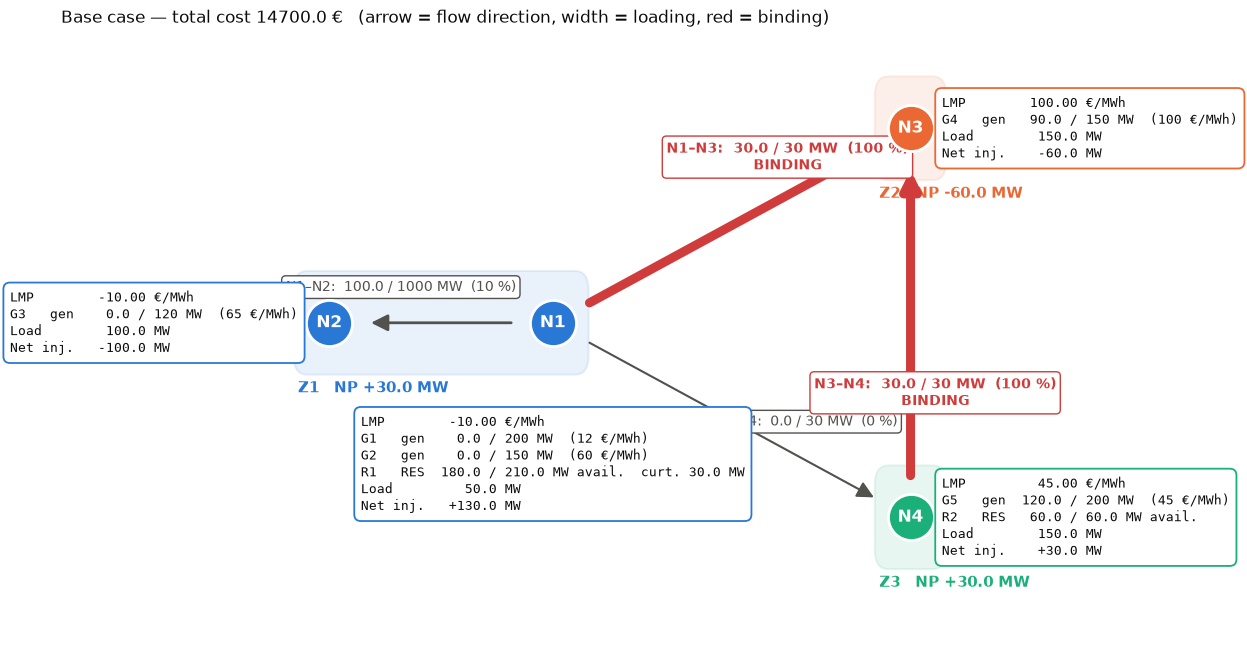

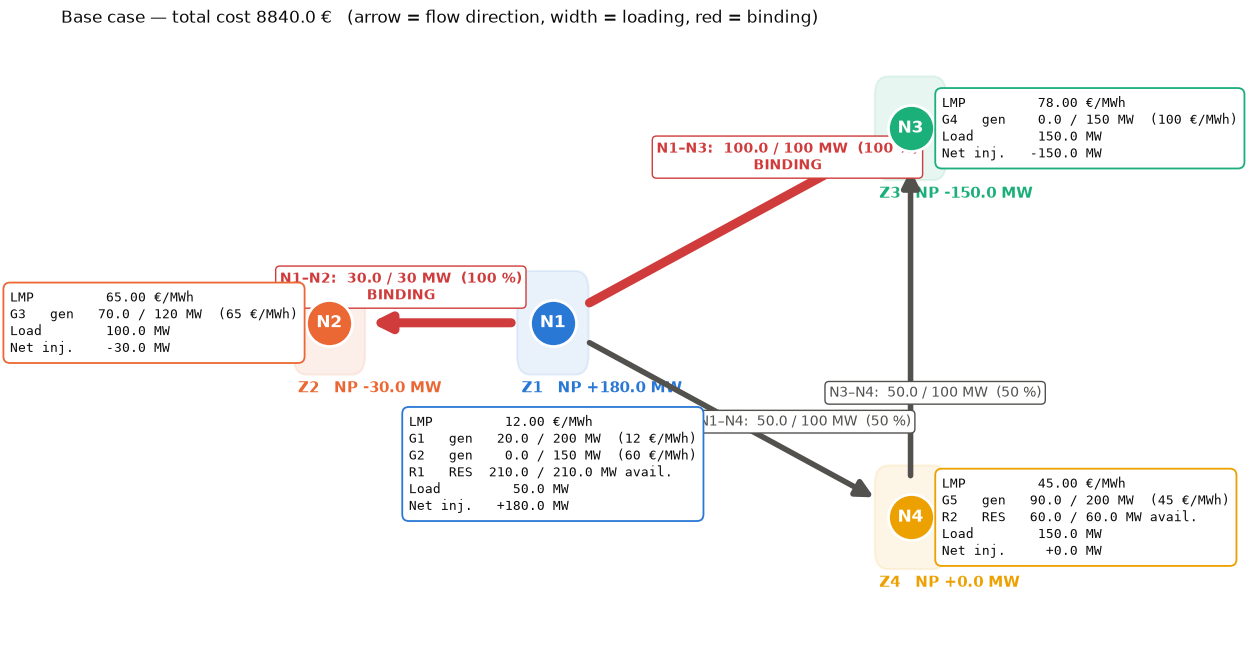

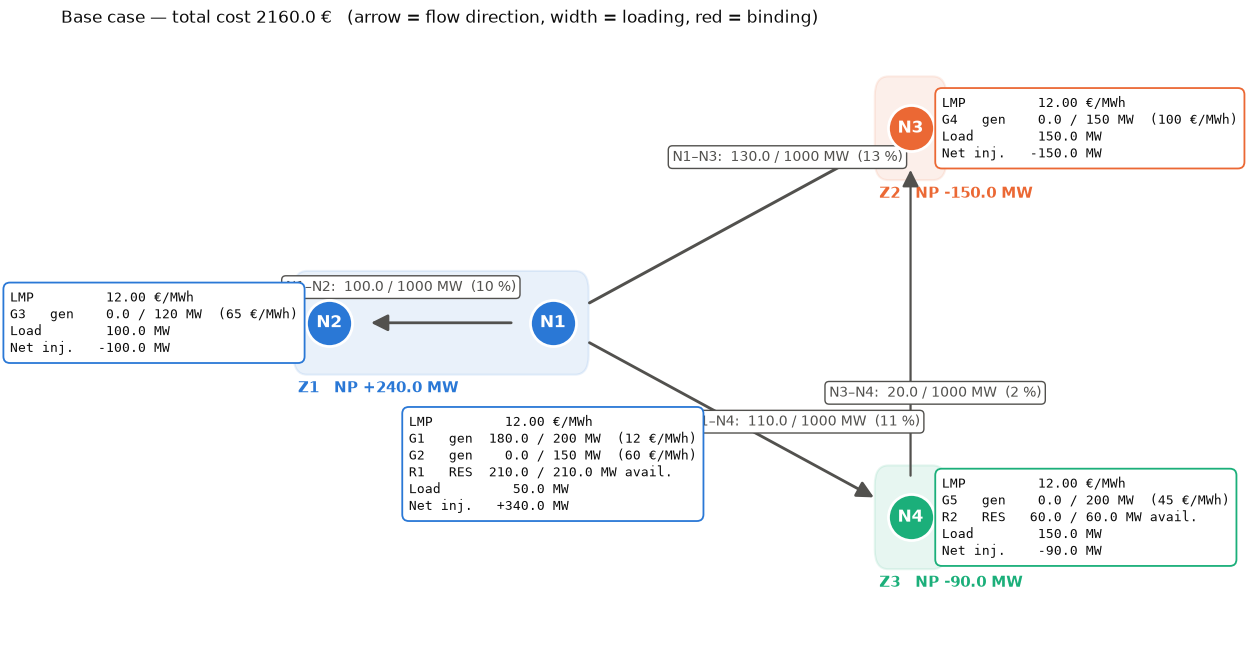

In [5]:
plot_network(data_crossborder, bc_crossborder)
plot_network(data_nodal_zones, bc_nodal_zones )
plot_network(data_no_congestion, bc_no_congestion )



In [6]:
CNE_crossborder = select_cne(data_crossborder, 0.05)
GSK_crossborder = gsk_online(data_crossborder, bc_crossborder)
parameters_crossborder = build_flow_based(data_crossborder, CNE_crossborder, bc_crossborder,gsk= GSK_crossborder)  

CNE_nodal_zones = select_cne(data_nodal_zones, 0.05)
GSK_nodal_zones = gsk_online(data_nodal_zones, bc_nodal_zones)
parameters_nodal_zones = build_flow_based(data_nodal_zones, CNE_nodal_zones, bc_nodal_zones,gsk= GSK_nodal_zones)  

CNE_no_congestion = select_cne(data_no_congestion, 0.05)
GSK_no_congestion = gsk_online(data_no_congestion, bc_no_congestion)
parameters_no_congestion = build_flow_based(data_no_congestion, CNE_no_congestion, bc_no_congestion,gsk= GSK_no_congestion)  


In [7]:
da_crossborder = da_zonal_clearing(data_crossborder, bc_crossborder, parameters_crossborder, Sigma = None, sigma_rel=0.0, verbose=False)
da_nodal_zones = da_zonal_clearing(data_nodal_zones, bc_nodal_zones, parameters_nodal_zones, Sigma = None, sigma_rel=0.0 , verbose=False)
da_no_congestion = da_zonal_clearing(data_no_congestion, bc_no_congestion, parameters_no_congestion, Sigma = None, sigma_rel=0.0 , verbose=False)

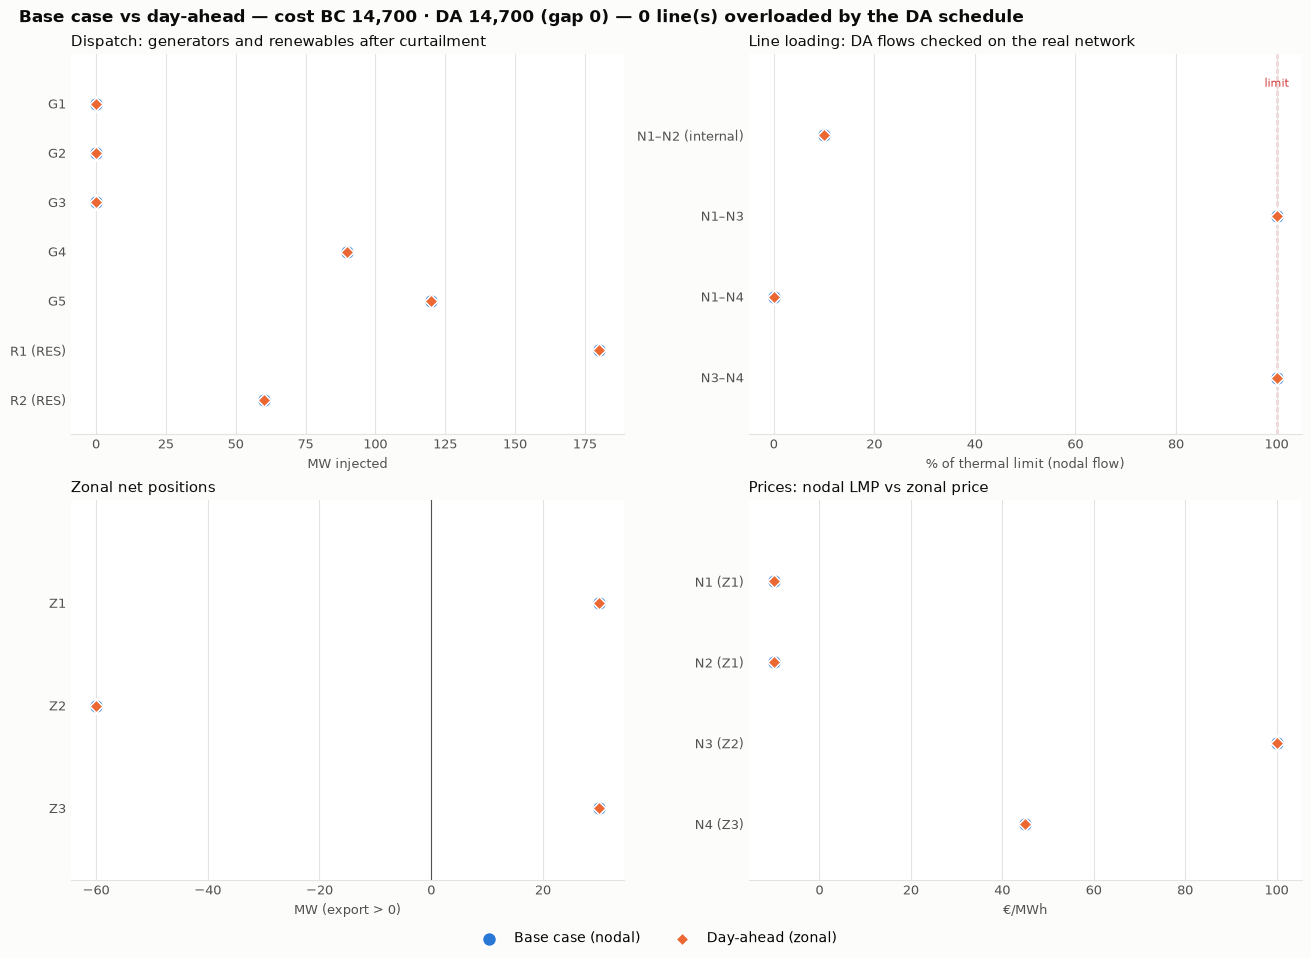

In [8]:
import numpy as np
import matplotlib.pyplot as plt

BC_COLOR, DA_COLOR = "#2a78d6", "#eb6834"      # fixed identity: BC = blue, DA = orange
INK, INK_2, GRID, ALERT = "#0b0b0b", "#52514e", "#e4e3df", "#d03b3b"


def _dumbbell(ax, labels, bc, da, unit, limit=None, alert=None):
    """One row per item: grey connector + BC dot + DA dot. alert: bool mask -> red label."""
    y = np.arange(len(labels))[::-1]
    for yi, b, d in zip(y, bc, da):
        ax.plot([b, d], [yi, yi], color=GRID, lw=3, zorder=1, solid_capstyle="round")
    ax.scatter(bc, y, s=110, color=BC_COLOR, zorder=3, edgecolor="white", linewidth=1.5, label="Base case (nodal)")
    ax.scatter(da, y, s=45, marker="D", color=DA_COLOR, zorder=4, edgecolor="white", linewidth=1.2,
               label="Day-ahead (zonal)")             # smaller diamond on top: both stay visible when equal
    for yi, b, d in zip(y, bc, da):                      # label only the delta, only if it matters
        delta = d - b
        if abs(delta) > 1e-3 * max(1, np.abs(np.r_[bc, da]).max()):
            ax.annotate(f"{delta:+.1f}", (max(b, d), yi), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK_2)
    if limit is not None:
        ax.axvline(limit, color=ALERT, lw=1, ls="--", zorder=0)
        ax.text(limit, y.max() + 0.6, "limit", color=ALERT, fontsize=8, ha="center")
    ax.set_yticks(y, labels)
    if alert is not None:
        for tick, a in zip(ax.get_yticklabels(), alert):
            if a:
                tick.set_color(ALERT); tick.set_fontweight("bold")
    ax.set_xlabel(unit, color=INK_2, fontsize=9)
    ax.set_ylim(y.min() - 0.7, y.max() + 1.0)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, length=0, labelsize=9)


def plot_bc_vs_da(data, bc, da, load=None, res=None):
    """Compare nodal base case (bc) and zonal day-ahead clearing (da) on one figure."""
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)
    v = lambda x: np.asarray(x, float).ravel()

    g_bc, g_da = v(bc["g"]), v(da["G"])
    c_bc, c_da = v(bc["C"]), v(da["C"])

    # Flows the DA schedule would really cause on the nodal network
    P_da = data.M_ng @ g_da + data.M_nr @ (r - c_da) - data.M_nd @ d
    f_bc, f_da = v(bc["f"]), data.PTDF @ P_da
    cap = data.line_cap_vec
    load_bc, load_da = 100 * np.abs(f_bc) / cap, 100 * np.abs(f_da) / cap

    # Prices: nodal LMP vs the zonal price of each node's zone
    zone_price = dict(zip(data.ZONES, v(da["price"])))
    p_bc = v(bc["LMP"])
    p_da = np.array([zone_price[data.node_zone[n]] for n in data.NODES])

    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), layout="constrained")
    fig.patch.set_facecolor("#fcfcfb")

    _dumbbell(axes[0, 0],
              [f"{g}" for g in data.GENERATORS] + [f"{x} (RES)" for x in data.RENEWABLES],
              np.r_[g_bc, r - c_bc], np.r_[g_da, r - c_da], "MW injected")
    axes[0, 0].set_title("Dispatch: generators and renewables after curtailment", loc="left", fontsize=11, color=INK)

    over = load_da > 100 + 1e-6
    _dumbbell(axes[0, 1], [f"{a}–{b}" + ("" if (a, b) in data.inter_lines else " (internal)")
                          for a, b in data.lines], load_bc, load_da,
              "% of thermal limit (nodal flow)", limit=100, alert=over)
    axes[0, 1].set_title("Line loading: DA flows checked on the real network", loc="left", fontsize=11, color=INK)

    _dumbbell(axes[1, 0], list(data.ZONES), v(bc["NP"]), v(da["NP"]), "MW (export > 0)")
    axes[1, 0].axvline(0, color=INK_2, lw=0.8)
    axes[1, 0].set_title("Zonal net positions", loc="left", fontsize=11, color=INK)

    _dumbbell(axes[1, 1], [f"{n} ({data.node_zone[n]})" for n in data.NODES], p_bc, p_da, "€/MWh")
    axes[1, 1].set_title("Prices: nodal LMP vs zonal price", loc="left", fontsize=11, color=INK)

    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=2, frameon=False, fontsize=10)
    gap = bc["cost"] - da["cost"]
    fig.suptitle(f"Base case vs day-ahead — cost BC {bc['cost']:,.0f} · DA {da['cost']:,.0f} "
                 f"(gap {gap:,.0f}) — {int(over.sum())} line(s) overloaded by the DA schedule",
                 x=0.01, ha="left", fontsize=12, color=INK, fontweight="bold")
    return fig

fig = plot_bc_vs_da(data_crossborder, bc_crossborder, da_crossborder)
plt.show()


In [9]:
bc_nodal_zones['LMP']

N1    12.0
N2    65.0
N3    78.0
N4    45.0
dtype: float64

In [10]:
da_nodal_zones['price']

Z1    12.0
Z2    65.0
Z3    78.0
Z4    45.0
dtype: float64

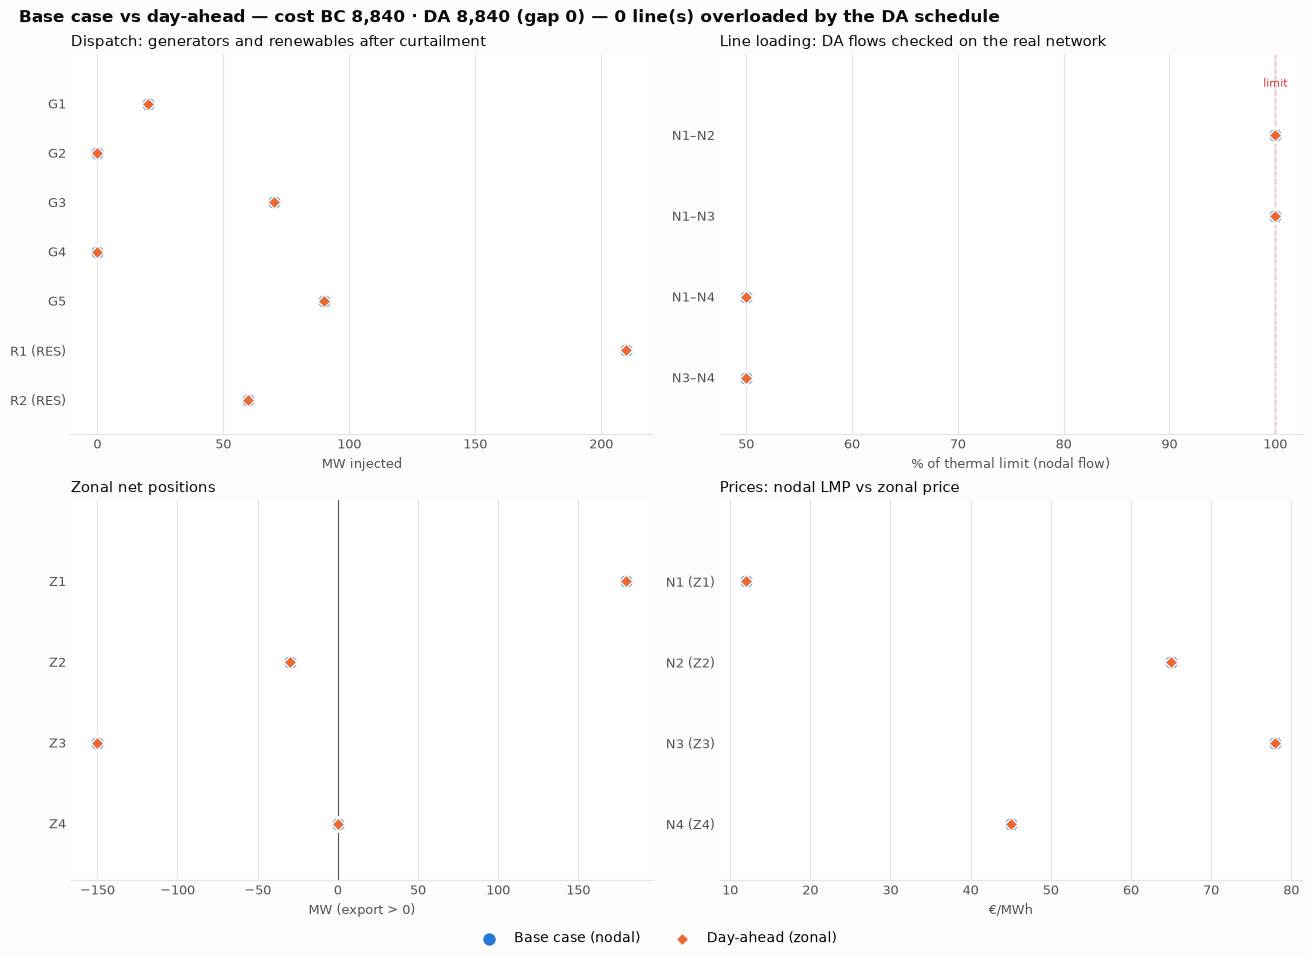

In [11]:
fig = plot_bc_vs_da(data_nodal_zones, bc_nodal_zones, da_nodal_zones)
plt.show()

In [12]:
display(bc_no_congestion["LMP"], da_no_congestion["price"])

N1    12.0
N2    12.0
N3    12.0
N4    12.0
dtype: float64

Z1    12.0
Z2    12.0
Z3    12.0
dtype: float64

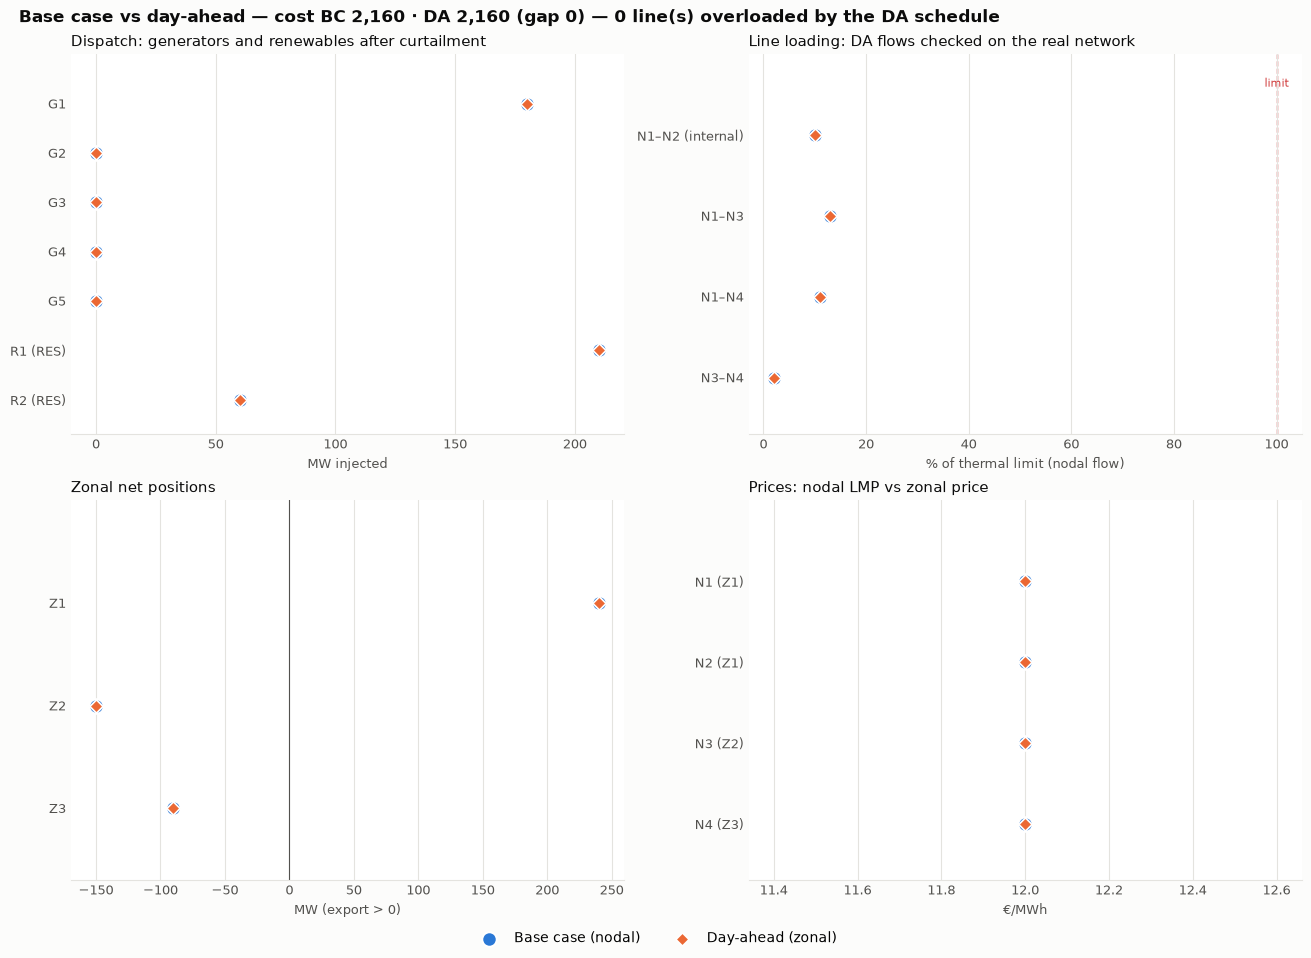

In [13]:
fig = plot_bc_vs_da(data_no_congestion, bc_no_congestion, da_no_congestion)
plt.show()

In [14]:
dispatch_crossborder = solve_redispatch(data_crossborder, da_crossborder, seed=None)        # set seed=<int> to fix the realization


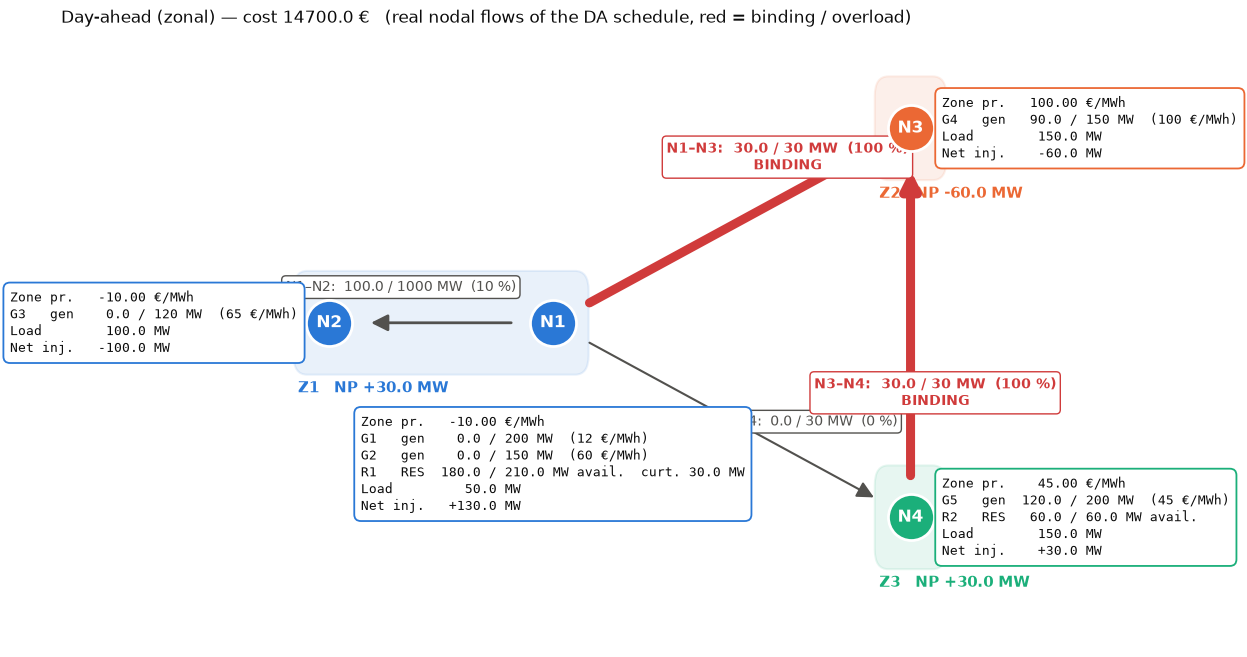

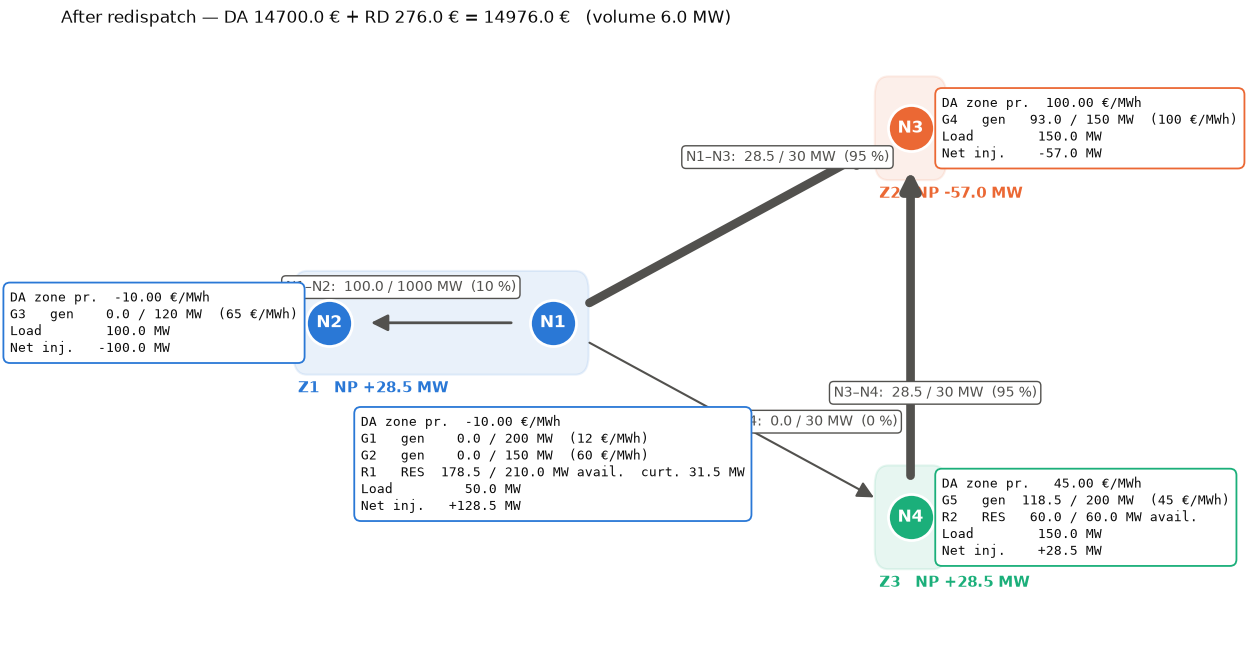

In [15]:
def to_network_result(data, res_, d, r, price, cost):
    """Turn a DA / redispatch result into the dict plot_network expects (g, C, P, f, NP, LMP, cost)."""
    G, C = res_["G"].values, res_["C"].values
    P = data.M_ng @ G + data.M_nr @ (r - C) - data.M_nd @ d          # nodal injections on the real network
    zone_price = dict(zip(data.ZONES, np.asarray(price, float)))
    return dict(g=res_["G"], C=res_["C"],
                P=pd.Series(P, index=data.NODES),
                f=pd.Series(data.PTDF @ P, index=data.lines),
                NP=pd.Series(data.M_zn @ P, index=data.ZONES),
                LMP=pd.Series([zone_price[data.node_zone[n]] for n in data.NODES], index=data.NODES),
                cost=cost)


d, r = data_crossborder.expected_DA_load_vec, data_crossborder.expected_DA_res_vec

# DA: zonal schedule, flows it really causes on the nodal network
da_net = to_network_result(data_crossborder, da_crossborder, d, r, da_crossborder["price"], da_crossborder["cost"])
plot_network(data_crossborder, da_net, load=d, res=r, price_label="Zone pr.",
             title=f"Day-ahead (zonal) — cost {da_crossborder['cost']:.1f} €   "
                   f"(real nodal flows of the DA schedule, red = binding / overload)")
plt.show()

# Redispatch: final dispatch after RD, with the RES availability RD was solved with
r_rd = dispatch_crossborder["r"].values
rd_net = to_network_result(data_crossborder, dispatch_crossborder, d, r_rd, da_crossborder["price"], da_crossborder["cost"] + dispatch_crossborder["cost"])
plot_network(data_crossborder, rd_net, load=d, res=r_rd, price_label="DA zone pr.",
             title=f"After redispatch — DA {da_crossborder['cost']:.1f} € + RD {dispatch_crossborder['cost']:.1f} € "
                   f"= {da_crossborder['cost'] + dispatch_crossborder['cost']:.1f} €   (volume {dispatch_crossborder['volume']:.1f} MW)")
plt.show()

# VOILT 


=== BASE CASE (nodal)   cost 8496.0


,N1,N2,N3,N4
P,-110.0,130.0,30.0,-50.0
LMP,50.0,-0.8,80.0,65.0


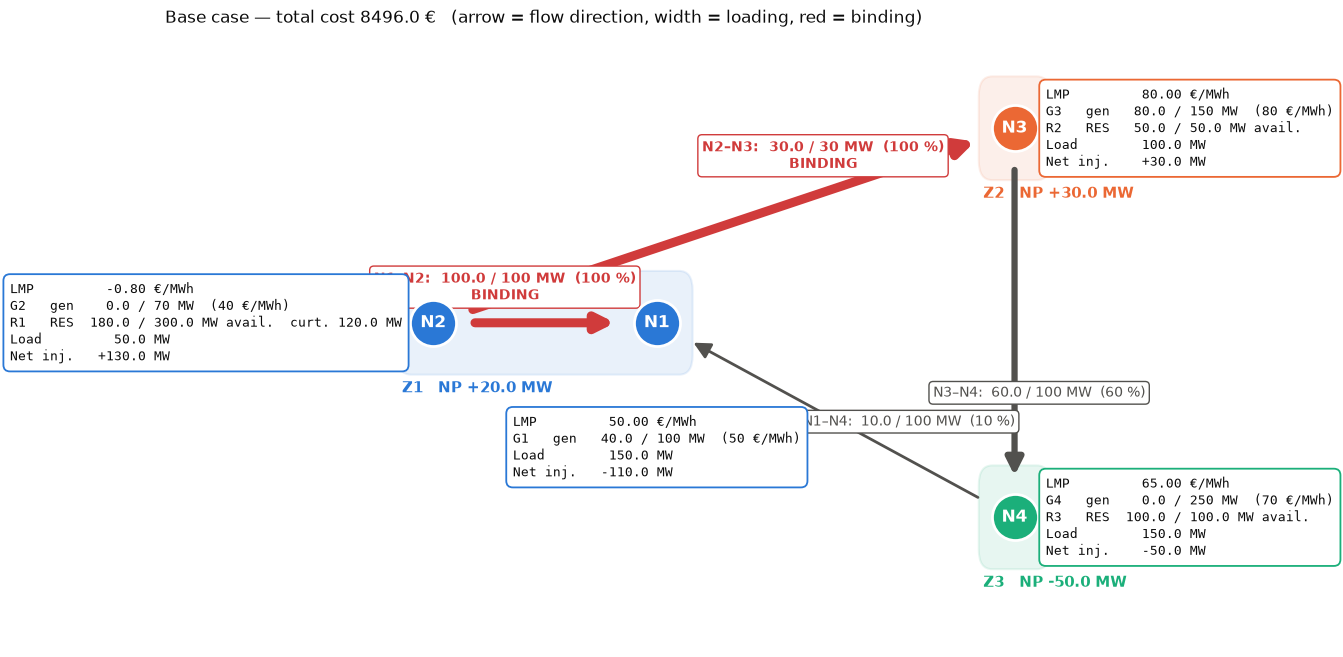

=== FLOW-BASED   GSK online:


,Z1,Z2,Z3
N1,0.182,0.0,0.0
N2,0.818,0.0,0.0
N3,0.000,1.0,0.0
N4,0.000,0.0,1.0


,F_ref,F0,RAM+,RAM-
"(N1, N2)",-100.0,-85.23,185.23,14.77
"(N1, N4)",-10.0,-28.41,128.41,71.59
"(N2, N3)",30.0,28.41,1.59,58.41
"(N3, N4)",60.0,28.41,71.59,128.41


=== DAY-AHEAD (zonal)   cost 6464.0


,G1,G2,G3,G4
G,0.0,0.0,80.0,0.0
alpha,0.0,0.0,1.0,0.0


,Z1,Z2,Z3
NP,20.0,30.0,-50.0
price,-0.8,80.0,70.0


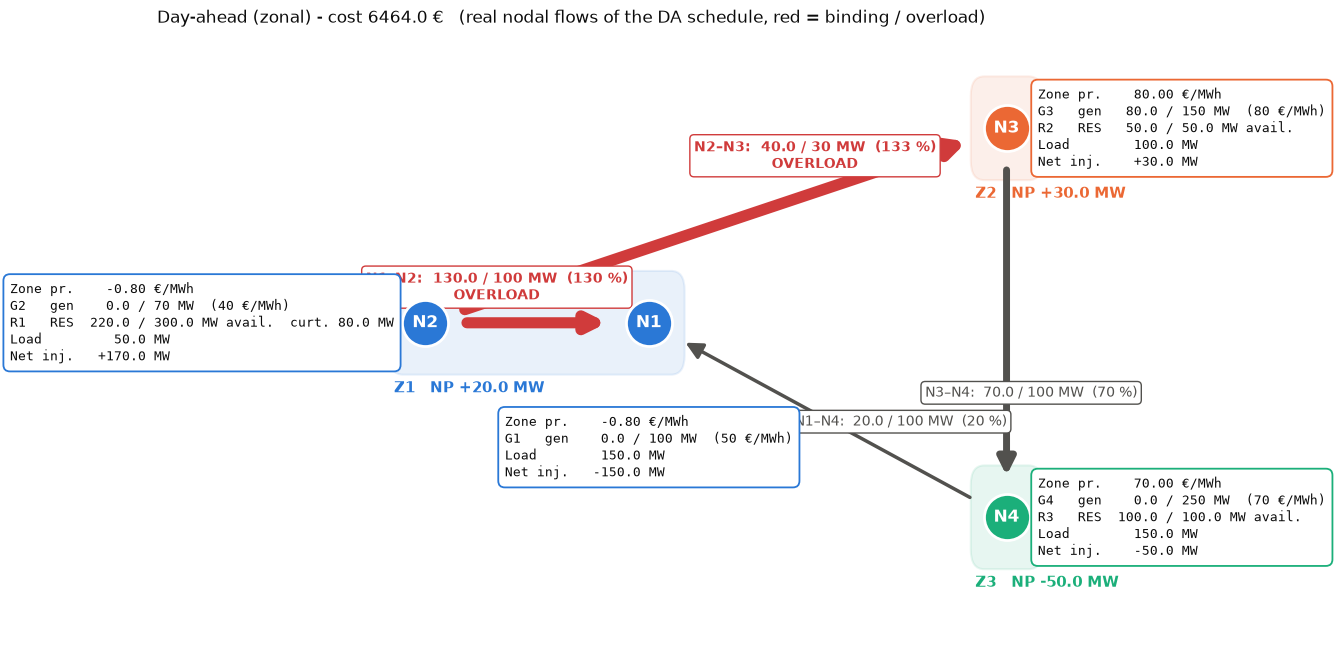

=== REDISPATCH   cost 2823.1   volume 94.3 MW


,R1,R2,R3
forecast,300.0,50.0,100.0
realized,300.0,50.0,98.7
C_DA,80.0,0.0,0.0
C_final,126.5,0.0,0.0


,G1,G2,G3,G4
G_DA,0.0,0.0,80.0,0.0
up,47.4,0.0,0.4,0.0
down,0.0,0.0,0.0,0.0
G_final,47.4,0.0,80.4,0.0


,"(N1, N2)","(N1, N4)","(N2, N3)","(N3, N4)"
f_BC,-100.0,-10.0,30.0,60.0
f_DA,-130.0,-20.0,40.0,70.0
f_RD,-95.0,-7.6,28.5,58.9
cap,100.0,100.0,30.0,100.0


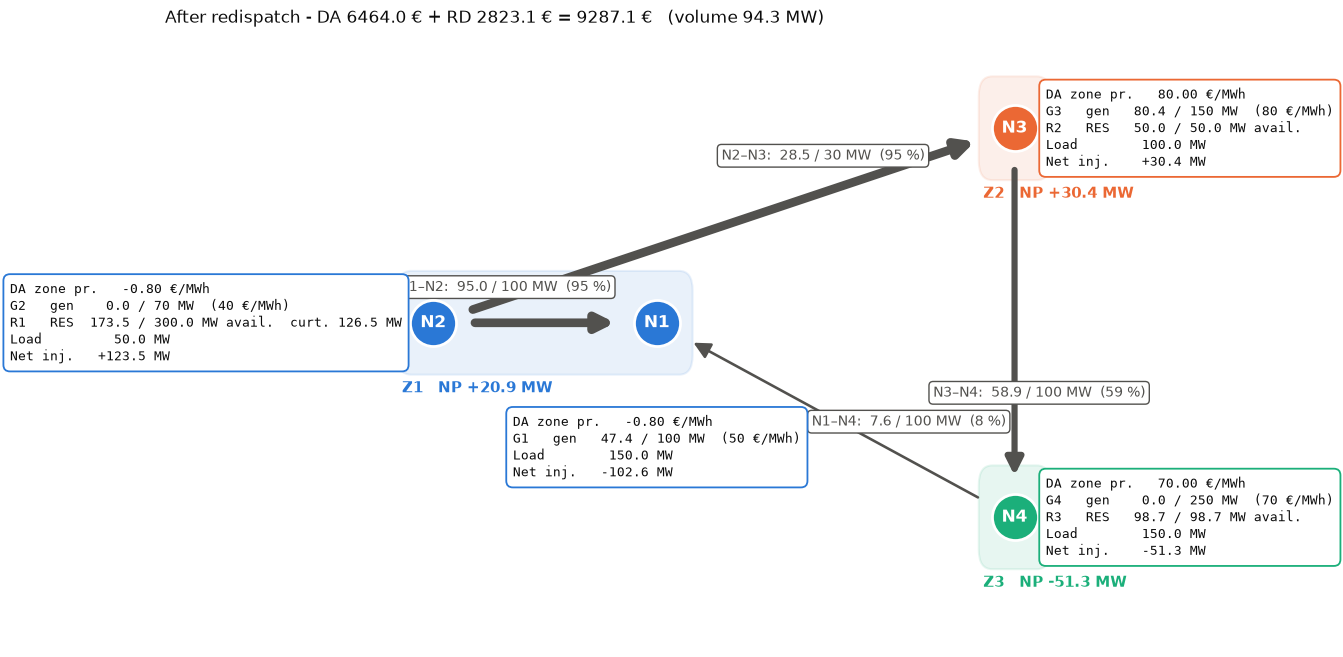

=== COSTS
  nodal base case        :     8496.0
  zonal DA               :     6464.0
  redispatch (seed 0)    :     2823.1
  zonal total (DA + RD)  :     9287.1
  cost of zonal vs nodal :      791.1
  RD over 200 draws      : mean 3178.1  [p5 2714.2, p95 4194.7]


In [18]:
# Full pipeline on data/voitl: base case -> flow-based domain -> DA (zonal, CC) -> redispatch
import matplotlib.pyplot as plt
from IPython.display import display

data_voitl = PowerSystemData.from_csv('../data/voitl')
r_v, d_v = data_voitl.expected_DA_res_vec, data_voitl.expected_DA_load_vec


def to_network_result(data, res_, d, r, price, cost):
    """DA / redispatch result -> dict plot_network expects (g, C, P, f, NP, LMP, cost)."""
    P = data.M_ng @ res_["G"].values + data.M_nr @ (r - res_["C"].values) - data.M_nd @ d
    zone_price = dict(zip(data.ZONES, np.asarray(price, float)))
    return dict(g=res_["G"], C=res_["C"], P=pd.Series(P, index=data.NODES),
                f=pd.Series(data.PTDF @ P, index=data.lines),
                NP=pd.Series(data.M_zn @ P, index=data.ZONES),
                LMP=pd.Series([zone_price[data.node_zone[n]] for n in data.NODES], index=data.NODES),
                cost=cost)


# 1. Base case (nodal)
bc_voitl = solve_base_case(data_voitl)
print(f"=== BASE CASE (nodal)   cost {bc_voitl['cost']:.1f}")
display(pd.DataFrame({"P": bc_voitl["P"], "LMP": bc_voitl["LMP"]}).T.round(2))
plot_network(data_voitl, bc_voitl)
plt.show()

# 2. Flow-based domain (online GSK)
CNE_voitl = select_cne(data_voitl, 0.05)
GSK_voitl = gsk_online(data_voitl, bc_voitl)
parameters_voitl = build_flow_based(data_voitl, CNE_voitl, bc_voitl, gsk=GSK_voitl)
K = len(CNE_voitl)
print("=== FLOW-BASED   GSK online:")
display(pd.DataFrame(GSK_voitl, index=data_voitl.NODES, columns=data_voitl.ZONES).round(3))
display(pd.DataFrame({"F_ref": parameters_voitl["F_ref"], "F0": parameters_voitl["F0"],
                      "RAM+": parameters_voitl["RAM"][:K], "RAM-": parameters_voitl["RAM"][K:]},
                     index=CNE_voitl).round(2))

# 3. Day-ahead (zonal, chance constraints)
da_voitl = da_zonal_clearing(data_voitl, bc_voitl, parameters_voitl, sigma_rel=0.1)
da_voitl_net = to_network_result(data_voitl, da_voitl, d_v, r_v, da_voitl["price"], da_voitl["cost"])
print(f"=== DAY-AHEAD (zonal)   cost {da_voitl['cost']:.1f}")
display(pd.DataFrame({"G": da_voitl["G"], "alpha": da_voitl["alpha"]}).T.round(2))
display(pd.DataFrame({"NP": da_voitl["NP"], "price": da_voitl["price"]}).T.round(2))
plot_network(data_voitl, da_voitl_net, load=d_v, res=r_v, price_label="Zone pr.",
             title=f"Day-ahead (zonal) - cost {da_voitl['cost']:.1f} €   "
                   f"(real nodal flows of the DA schedule, red = binding / overload)")
plt.show()

# 4. Redispatch (RES realization drawn from the CC distribution)
rd_voitl = solve_redispatch(data_voitl, da_voitl, seed=0)          # seed=None for a new draw each run
rd_voitl_net = to_network_result(data_voitl, rd_voitl, d_v, rd_voitl["r"].values,
                                 da_voitl["price"], da_voitl["cost"] + rd_voitl["cost"])
print(f"=== REDISPATCH   cost {rd_voitl['cost']:.1f}   volume {rd_voitl['volume']:.1f} MW")
display(pd.DataFrame({"forecast": da_voitl["r_forecast"], "realized": rd_voitl["r"],
                      "C_DA": da_voitl["C"], "C_final": rd_voitl["C"]}).T.round(1))
display(pd.DataFrame({"G_DA": da_voitl["G"], "up": rd_voitl["up"], "down": rd_voitl["down"],
                      "G_final": rd_voitl["G"]}).T.round(1))
display(pd.DataFrame({"f_BC": bc_voitl["f"].values, "f_DA": da_voitl_net["f"].values,
                      "f_RD": rd_voitl["f"].values, "cap": data_voitl.line_cap_vec},
                     index=data_voitl.lines).T.round(1))
plot_network(data_voitl, rd_voitl_net, load=d_v, res=rd_voitl["r"].values, price_label="DA zone pr.",
             title=f"After redispatch - DA {da_voitl['cost']:.1f} € + RD {rd_voitl['cost']:.1f} € "
                   f"= {da_voitl['cost'] + rd_voitl['cost']:.1f} €   (volume {rd_voitl['volume']:.1f} MW)")
plt.show()

# 5. Costs, and redispatch over many RES draws
rd_draws = [solve_redispatch(data_voitl, da_voitl, seed=s) for s in range(200)]
rd_cost = np.array([x["cost"] for x in rd_draws])
print(f"""=== COSTS
  nodal base case        : {bc_voitl['cost']:10.1f}
  zonal DA               : {da_voitl['cost']:10.1f}
  redispatch (seed 0)    : {rd_voitl['cost']:10.1f}
  zonal total (DA + RD)  : {da_voitl['cost'] + rd_voitl['cost']:10.1f}
  cost of zonal vs nodal : {da_voitl['cost'] + rd_voitl['cost'] - bc_voitl['cost']:10.1f}
  RD over 200 draws      : mean {rd_cost.mean():.1f}  [p5 {np.percentile(rd_cost, 5):.1f}, p95 {np.percentile(rd_cost, 95):.1f}]""")